# Flight arrival-delay classification — CatBoost

    Author: Ridhima Singhal. Target: `Arrival_Delay`, 0 = not delayed, 1 = delayed.

    Put this notebook beside the three supplied CSV files, select a Python kernel in VS Code and **Run All**. The last cell trains on all labelled rows and generates **`catboost.csv`** beside the input Flight CSV. No output folders are created. The complete run can take several minutes. No other custom Python files or notebooks are required.

    Kaggle uses **accuracy**, as confirmed by the student. Model/cutoff selection therefore uses internal validation accuracy. Weighted F1, macro F1 and delayed-class F1 are reported separately. A goal is not a measured result: the notebook prints whether accuracy and weighted F1 each reach 0.87. Kaggle public/private scores are not available locally.

## Read this scope condition before using the results

        **This is an experimental model for the supplied ordered batches. It uses CSV row order as additional information beyond the listed attributes.** Nearby within-day rows have useful timing relationships. We construct leave-one-out monotone clock estimates and neighbour clock differences; these are proxies, not observed scheduled-departure times. The sorting mechanism is an inference from the supplied files, not a documented attribute.

        Predictions depend on the composition and order of the batch. Preserve the original CSV order and predict the full unknown file together. This method does not support arbitrary shuffled files or independent single-flight predictions. Explain this assumption explicitly in your assignment; its applicability depends on whether source-file order is permitted and meaningful in the assessment. The `catboost_no_order.ipynb` alternative uses only listed attributes and fitted historical statistics.

        Training, validation, holdout and unknown contexts are constructed **separately**. No holdout labels, unknown labels or neighbouring rows from another partition enter a batch's context. Only the supplied training labels fit the historical-reference statistics. A shuffled-order validation control below quantifies dependence on file order.

In [15]:
# Dependencies are pinned in requirements.txt (repo root): pip install -r requirements.txt

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 3.8 MB/s eta 0:00:27
    --------------------------------------- 1.8/101.7 MB 4.5 MB/s eta 0:00:23
   - -------------------------------------- 2.9/101.7 MB 4.6 MB/s eta 0:00:22
   - -------------------------------------- 4.2/101.7 MB 5.0 MB/s eta 0:00:20
   -- ------------------------------------- 5.2/101.7 MB 5.2 MB/s eta 0:00:19
   -- ------------------------------------- 6.6/101.7 MB 5.2 MB/s eta 0:00:19
   -- ------------------------------------- 7.6/101.7 MB 5.3 MB/s eta 0:00:18
   --- ------------------------------------ 8.7/101.7 MB 5.3 MB/s eta 0:00:18
   --- ------------------------------------ 8.7/101.7 MB 5.3 MB/s eta 0:00:18
   --- ------------------------------------ 9.2/101.7 MB 4.3 MB/s eta 0:00:22
   ---- ----------------------------------- 10.2/101.7 MB 4.4 MB/s eta 0:00:21

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Environment and inputs

    If an import fails, uncomment the install line, run it, restart the kernel, then Run All. The tested environment used Python 3.12 and scikit-learn 1.8.0. The initial run keeps the selected configuration; optional `RUN_TUNING=True` rechecks the recorded candidate settings and selects on training-only validation.

In [16]:
# %pip install numpy==2.3.5 pandas==2.2.3 scipy==1.17.0 scikit-learn==1.8.0 matplotlib ipykernel catboost==1.2.10

In [17]:
from pathlib import Path
from copy import deepcopy
import time,platform,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display,FileLink
from scipy.optimize import isotonic_regression
from sklearn.isotonic import IsotonicRegression
from sklearn.base import BaseEstimator,TransformerMixin
from sklearn.model_selection import train_test_split,StratifiedKFold,KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import TargetEncoder,QuantileTransformer,RobustScaler,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,
    recall_score,f1_score,roc_auc_score,classification_report,ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

SEED=42
TARGET='Arrival_Delay'
RUN_TUNING=False
THRESHOLD_OBJECTIVE='accuracy'  # Kaggle metric; 'weighted_f1' is an optional local objective.
OUTPUT_STEM='catboost'
print('Python:',platform.python_version(),'| scikit-learn:',sklearn.__version__)
print('pandas:',pd.__version__,'| NumPy:',np.__version__)

Python: 3.14.6 | scikit-learn: 1.9.1
pandas: 3.0.6 | NumPy: 2.5.3


In [18]:
# Optional: set DATA_DIR = Path(r'C:\Users\your_name\flight_project') on Windows.
DATA_DIR = None
folders = ([Path(DATA_DIR)] if DATA_DIR is not None else
           [Path.cwd(), Path.cwd()/'data', Path.cwd().parent/'data', Path.cwd()/'upload'])

def find_file(names):
    for folder in folders:
        for name in names:
            path = folder/name
            if path.is_file():
                return path.resolve()
    raise FileNotFoundError('Put one of these files beside the notebook, or set DATA_DIR: ' + ', '.join(names))

TRAIN_FILE = find_file(['Flight-Dataset.csv', 'Flight-Dataset(1).csv', 'Flight-Dataset (1).csv'])
UNKNOWN_FILE = find_file(['Unknown-Dataset.csv', 'Unknown-Dataset(1).csv', 'Unknown-Dataset (1).csv'])
SAMPLE_FILE = find_file(['Kaggle Submission-Sample.csv', 'Kaggle Submission-Sample (2).csv', 'Kaggle Submission-Sample(1).csv'])
train = pd.read_csv(TRAIN_FILE)
unknown = pd.read_csv(UNKNOWN_FILE)
sample = pd.read_csv(SAMPLE_FILE, dtype={'row ID': str})

assert TARGET in train and train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}
assert TARGET not in unknown, 'Unknown data should not have target labels.'
assert set(train.columns) - {TARGET} == set(unknown.columns)
assert list(sample.columns) == ['row ID', 'Predicted_Arrival_Delay']
assert len(sample) == len(unknown) and sample['row ID'].notna().all() and sample['row ID'].is_unique
X = train.drop(columns=TARGET)
y = train[TARGET].astype(int)
unknown = unknown[X.columns].copy()
print('Labelled rows:', len(train), '| Unknown rows:', len(unknown))
print('Exact duplicate labelled rows:', train.duplicated().sum())
display(y.value_counts().rename_axis('class').to_frame('count'))
display(pd.DataFrame({'training_missing_%': X.isna().mean()*100,
                      'unknown_missing_%': unknown.isna().mean()*100}).round(2))

Labelled rows: 42634 | Unknown rows: 21318
Exact duplicate labelled rows: 0


,count
class,
0,28637
1,13997


,training_missing_%,unknown_missing_%
O_CITY,5.03,7.0
O_STATE,0.00,0.0
D_CITY,0.00,0.0
D_STATE,0.00,0.0
DEPARTURE_TIME,0.00,0.0
SCHEDULED_TIME,5.03,10.0
ELAPSED_TIME,0.00,7.0
AIR_TIME,0.00,10.0
DISTANCE,8.00,7.0
WHEELS_ON,5.71,0.0


In [19]:
for name,frame in [('Flight',X),('Unknown',unknown)]:
    dates=pd.to_datetime(frame.DATE,format='%Y-%m-%d',errors='coerce')
    print(name,'known dates in chronological file order:',dates.dropna().is_monotonic_increasing)
# Do not sort the raw data by actual departure time. Its supplied within-day
# order is precisely the extra information used by the batch-context variant.

Flight known dates in chronological file order: True
Unknown known dates in chronological file order: True


## Evaluation protocol

    The fixed split is **80% training / 20% holdout**, stratified with seed 42, matching earlier work. Within the 80%, a seed-17 stratified split supplies 60% of all records for fitting and 20% for validation. Hyperparameters, boosting iteration counts and cutoffs are selected on that internal validation set. The chosen configuration is then fitted on the full 80% and evaluated on the 20% holdout.

    The same holdout was viewed in earlier model development, so this is a development comparison, not a pristine blind final test. Choices in this notebook are made before its holdout evaluation. Neither Kaggle public scores nor the sample's placeholder predictions are used for fitting or selection.

In [20]:
X_train,X_holdout,y_train,y_holdout=train_test_split(
    X,y,test_size=.2,stratify=y,random_state=42)
X_fit,X_val,y_fit,y_val=train_test_split(
    X_train,y_train,test_size=.25,stratify=y_train,random_state=17)
assert set(X_fit.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_holdout.index)
print('Training:',len(X_train),'| Holdout:',len(X_holdout))
print('Internal fit:',len(X_fit),'| Internal validation:',len(X_val))

Training: 34107 | Holdout: 8527
Internal fit: 25580 | Internal validation: 8527


## Features and missing values

    `SCHEDULED_TIME` is the planned flight duration. Duration overrun, ground time, estimated taxi-out, clock cycles, actual gate-arrival clock and timing remainders are derived from the supplied attributes. Route medians support missing-value imputation. Where possible, a missing elapsed duration is reconstructed using wheels-on minus departure, a fitting-data route time-zone offset and taxi-in time. These are learned only from fitting rows. Unrecoverable values retain fitted-median fallbacks.

    Historical day, origin/day, destination/day, airline/day, route/weekday and local departure-clock delay rates are **cross-fitted on unique fitting rows**. Each training row's fold is excluded when generating its historical label features. Validation, holdout and unknown rows use reference tables learned only from the current fitting partition. No external flight records or hidden labels are used.

    For batch-context models, four label-free density views (full batch and 1/2, 1/3, 1/4 thinnings) make training context more comparable to smaller prediction batches. Thinning is random and independent of labels. Some classifiers receive one randomly selected view per unique flight. Others use all four with total sample weight one per original flight. Target encoding of categories is performed on unique rows before views are repeated.

    These are retrospective models using actual departure, air/elapsed time and landing information. Their scores do not establish pre-departure forecasting performance.

In [21]:
class FlightFeatures(BaseEstimator, TransformerMixin):
    """Flight features; route statistics are fitted on the supplied training rows only."""
    def __init__(self, compact=False, aggregate=True):
        self.compact = compact
        self.aggregate = aggregate

    @staticmethod
    def clean(X):
        r = X.copy()
        for c in r.select_dtypes(include='object'):
            r[c] = r[c].str.strip().replace('', np.nan)
        return r

    @staticmethod
    def route(r):
        return r[['AIRLINE_NAME', 'O_CITY', 'O_STATE', 'D_CITY', 'D_STATE']].fillna('?').astype(str).agg('|'.join, axis=1)

    def fit(self, X, y=None):
        r = self.clean(X)
        self.keep_ = r.columns[r.nunique(dropna=True) > 1].tolist()
        self.schedule_ = r.SCHEDULED_TIME.groupby(self.route(r)).median().to_dict()
        self.air_ = r.AIR_TIME.groupby(self.route(r)).median().to_dict()
        self.distance_ = r.DISTANCE.groupby(self.route(r)).median().to_dict()
        self.global_schedule_ = r.SCHEDULED_TIME.median()
        self.global_air_ = r.AIR_TIME.median()
        self.global_distance_ = r.DISTANCE.median()
        return self

    def transform(self, X):
        r = self.clean(X)[self.keep_].copy()
        key = self.route(r)
        schedule = key.map(self.schedule_).fillna(self.global_schedule_)
        typical_air = key.map(self.air_).fillna(self.global_air_)
        typical_distance = key.map(self.distance_).fillna(self.global_distance_)
        for c in ['SCHEDULED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'WHEELS_ON']:
            r[c + '_MISSING'] = r[c].isna().astype(float)
        if self.aggregate:
            r['SCHEDULED_TIME'] = r.SCHEDULED_TIME.fillna(schedule)
            r['DISTANCE'] = r.DISTANCE.fillna(typical_distance)
            r['SCHEDULE_MINUS_ROUTE_MEDIAN'] = r.SCHEDULED_TIME - schedule
            r['ELAPSED_MINUS_ROUTE_SCHEDULE'] = r.ELAPSED_TIME - schedule
            r['AIR_MINUS_ROUTE_MEDIAN'] = r.AIR_TIME - typical_air
        date = pd.to_datetime(r.pop('DATE'), format='%Y-%m-%d', errors='coerce')
        r['MONTH'] = date.dt.month.astype(float)
        r['DAY_OF_WEEK'] = date.dt.dayofweek.astype(float)
        r['DAY_OF_YEAR'] = date.dt.dayofyear.astype(float)
        for c in ['DEPARTURE_TIME', 'WHEELS_ON']:
            t = pd.to_numeric(r.pop(c), errors='coerce')
            h, m = t // 100, t % 100
            valid = (h.between(0, 23) & m.between(0, 59)) | (t == 2400)
            minute = ((h * 60 + m) % 1440).where(valid)
            r[c + '_MINUTES'] = minute
            r[c + '_SIN'] = np.sin(2 * np.pi * minute / 1440)
            r[c + '_COS'] = np.cos(2 * np.pi * minute / 1440)
            if not self.compact:
                r[c + '_HOUR'] = minute // 60
                r[c + '_MINUTE_OF_HOUR'] = minute % 60
                r[c + '_REMAINDER_5'] = minute % 5
                r[c + '_REMAINDER_15'] = minute % 15
        r['DURATION_OVERRUN'] = r.ELAPSED_TIME - r.SCHEDULED_TIME
        r['GROUND_TIME'] = r.ELAPSED_TIME - r.AIR_TIME
        r['ESTIMATED_TAXI_OUT'] = r.GROUND_TIME - r.TAXI_IN
        r['DURATION_RATIO'] = r.ELAPSED_TIME / r.SCHEDULED_TIME.replace(0, np.nan)
        r['SCHEDULED_GROUND_SLACK'] = r.SCHEDULED_TIME - r.AIR_TIME
        r['AIR_SPEED'] = 60 * r.DISTANCE / r.AIR_TIME.replace(0, np.nan)
        r['ROUTE'] = r.O_CITY.fillna('?') + '|' + r.O_STATE.fillna('?') + '>' + r.D_CITY.fillna('?') + '|' + r.D_STATE.fillna('?')
        if self.compact:
            cols = ['DURATION_OVERRUN','GROUND_TIME','ESTIMATED_TAXI_OUT','TAXI_IN',
                    'SCHEDULED_GROUND_SLACK','SCHEDULED_TIME','DISTANCE',
                    'DEPARTURE_TIME_SIN','DEPARTURE_TIME_COS',
                    'WHEELS_ON_SIN','WHEELS_ON_COS','MONTH','DAY_OF_WEEK',
                    'AIRLINE_NAME','O_STATE','D_STATE','ROUTE','SCHEDULED_TIME_MISSING']
            if self.aggregate:
                cols += ['SCHEDULE_MINUS_ROUTE_MEDIAN','ELAPSED_MINUS_ROUTE_SCHEDULE','AIR_MINUS_ROUTE_MEDIAN']
            r = r[cols]
        return r.replace([np.inf, -np.inf], np.nan)

In [22]:
class FlightDataPreparation(BaseEstimator,TransformerMixin):
    def __init__(self,aggregate_features=True):self.aggregate_features=aggregate_features
    @staticmethod
    def clean(X):
        r=X.copy()
        for c in r.select_dtypes(exclude=np.number):
            r[c]=r[c].str.strip().replace('',np.nan).astype(object)
        return r
    @staticmethod
    def key(r,cols):
        return r[cols].fillna('?').astype(str).agg('|'.join,axis=1)
    def fit(self,X,y=None):
        r=self.clean(X)
        self.city_key_=['O_STATE','D_CITY','DISTANCE']
        a=r[r.O_CITY.notna() & r.DISTANCE.notna()].copy()
        self.city_map_=a.groupby(self.key(a,self.city_key_))['O_CITY'].agg(lambda s:s.mode().iloc[0]).to_dict()
        r['O_CITY']=r.O_CITY.fillna(self.key(r,self.city_key_).map(self.city_map_))
        self.group_fields_=[['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE'],['O_CITY','O_STATE','D_CITY','D_STATE'],['AIRLINE_NAME','DISTANCE']]
        self.numeric_=['SCHEDULED_TIME','ELAPSED_TIME','AIR_TIME','DISTANCE','TAXI_IN']
        self.group_tables_=[r.groupby(self.key(r,cols))[self.numeric_].median() for cols in self.group_fields_]
        self.global_=r[self.numeric_].median()
        # Time-zone difference, inferred without target labels.
        dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        land=(r.WHEELS_ON//100*60+r.WHEELS_ON%100)%1440
        offset=((land-dep-r.ELAPSED_TIME+r.TAXI_IN+720)%1440-720).round()
        offset=60*(offset/60).round()
        self.offset_map_=offset.groupby(self.key(r,self.group_fields_[1])).median().to_dict()
        self.offset_state_map_=offset.groupby(self.key(r,['O_STATE','D_STATE'])).median().to_dict()
        return self
    def transform(self,X):
        r=self.clean(X)
        for c in ['O_CITY','SCHEDULED_TIME','ELAPSED_TIME','AIR_TIME','DISTANCE','WHEELS_ON']:
            r[c+'_ORIGINALLY_MISSING']=r[c].isna().astype(int)
        r['O_CITY']=r.O_CITY.fillna(self.key(r,self.city_key_).map(self.city_map_))
        lookups=[]
        for cols,table in zip(self.group_fields_,self.group_tables_):
            k=self.key(r,cols)
            lookup=table.reindex(k.to_numpy()).set_axis(r.index)
            lookups.append(lookup)
        # Prefer route-specific medians over global values.
        for c in ['SCHEDULED_TIME','DISTANCE']:
            for lookup in lookups:r[c]=r[c].fillna(lookup[c])
            r[c]=r[c].fillna(self.global_[c])
        ref=lookups[0].fillna(lookups[1]).fillna(lookups[2]).fillna(self.global_)
        typical_ground=ref.ELAPSED_TIME-ref.AIR_TIME
        r['ELAPSED_TIME']=r.ELAPSED_TIME.fillna(r.AIR_TIME+typical_ground).fillna(ref.ELAPSED_TIME)
        r['AIR_TIME']=r.AIR_TIME.fillna(r.ELAPSED_TIME-typical_ground).fillna(ref.AIR_TIME)
        dep=(r.DEPARTURE_TIME//100*60+r.DEPARTURE_TIME%100)%1440
        offset=self.key(r,self.group_fields_[1]).map(self.offset_map_)
        offset=offset.fillna(self.key(r,['O_STATE','D_STATE']).map(self.offset_state_map_)).fillna(0)
        land=(dep+r.ELAPSED_TIME-r.TAXI_IN+offset)%1440
        estimated_wheels=land//60*100+land%60
        r['WHEELS_ON']=r.WHEELS_ON.fillna(estimated_wheels)
        if self.aggregate_features:
            r['SCHEDULE_MINUS_ROUTE_ELAPSED']=r.SCHEDULED_TIME-ref.ELAPSED_TIME
            r['ELAPSED_MINUS_ROUTE_MEDIAN']=r.ELAPSED_TIME-ref.ELAPSED_TIME
            r['AIR_MINUS_ROUTE_MEDIAN']=r.AIR_TIME-ref.AIR_TIME
            r['TAXI_IN_MINUS_ROUTE_MEDIAN']=r.TAXI_IN-ref.TAXI_IN
            r['SCHEDULE_MINUS_ROUTE_MEDIAN']=r.SCHEDULED_TIME-ref.SCHEDULED_TIME
        return r

In [23]:
class EnhancedFlightFeatures(BaseEstimator, TransformerMixin):
    """Physics-based missing-value recovery plus cross-fitted historical context.

    Only supplied fitting rows are used. No external flight data, row IDs,
    holdout labels or unknown labels enter the fitted statistics.
    """
    def __init__(self, history=True, folds=5):
        self.history=history
        self.folds=folds

    @staticmethod
    def key(r, columns):
        return r[columns].fillna('?').astype(str).agg('|'.join,axis=1)

    @staticmethod
    def minutes(s):
        h,m=s//100,s%100
        valid=(h.between(0,23)&m.between(0,59))|(s==2400)
        return ((h*60+m)%1440).where(valid)

    def prepare(self,X):
        r=self.domain_.transform(X)
        # Reconstruct a missing total duration using the clock identity:
        # wheels-on - departure = elapsed - taxi-in + time-zone offset (mod day).
        dep=self.minutes(r.DEPARTURE_TIME)
        observed_landing=self.minutes(X.WHEELS_ON)
        offset=self.key(r,self.domain_.group_fields_[1]).map(self.domain_.offset_map_)
        offset=offset.fillna(self.key(r,['O_STATE','D_STATE']).map(self.domain_.offset_state_map_))
        recovered=(observed_landing-dep-offset)%1440+r.TAXI_IN
        use=X.ELAPSED_TIME.isna()&recovered.between(15,1000)
        r.loc[use,'ELAPSED_TIME']=recovered[use]
        return r

    def keys(self,r):
        d=pd.to_datetime(r.DATE,format='%Y-%m-%d',errors='coerce')
        a=r.assign(DAY_KEY=d.dt.strftime('%Y-%m-%d').fillna('?'),
                   WEEKDAY=d.dt.dayofweek.fillna(-1).astype(int).astype(str),
                   DEPARTURE_BLOCK=(self.minutes(r.DEPARTURE_TIME)//120).astype(int).astype(str),
                   SCHEDULE_BIN=(r.SCHEDULED_TIME/10).round().astype(int).astype(str))
        return {
            'day':self.key(a,['DAY_KEY']),
            'origin_day':self.key(a,['O_CITY','O_STATE','DAY_KEY']),
            'destination_day':self.key(a,['D_CITY','D_STATE','DAY_KEY']),
            'airline_day':self.key(a,['AIRLINE_NAME','DAY_KEY']),
            'origin_block':self.key(a,['O_CITY','O_STATE','DEPARTURE_BLOCK']),
            'route_weekday':self.key(a,['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE','WEEKDAY']),
            'route':self.key(a,['AIRLINE_NAME','O_CITY','O_STATE','D_CITY','D_STATE']),
            'origin_airline':self.key(a,['AIRLINE_NAME','O_CITY','O_STATE'])}

    def fit(self,X,y=None):
        self.domain_=FlightDataPreparation(aggregate_features=True).fit(X)
        r=self.prepare(X)
        self.base_=FlightFeatures(compact=False,aggregate=True).fit(r)
        self.prior_=float(np.mean(y)) if y is not None else .33
        self.tables_={};self.references_={}
        if not self.history:return self
        keys=self.keys(r)
        for name,k in keys.items():
            tab=pd.DataFrame({'key':k.to_numpy(),'y':np.asarray(y),
                              'overrun':(r.ELAPSED_TIME-r.SCHEDULED_TIME).to_numpy(),
                              'taxi_out':(r.ELAPSED_TIME-r.AIR_TIME-r.TAXI_IN).to_numpy()})
            self.tables_[name]=tab.groupby('key',sort=False).agg(
                n=('y','size'),positive=('y','sum'),
                overrun=('overrun','median'),taxi_out=('taxi_out','median'))
        for kind in ['route','origin_airline']:
            frame=pd.DataFrame({'key':keys[kind].to_numpy(),
                'departure':self.minutes(r.DEPARTURE_TIME).to_numpy(),
                'duration':r.SCHEDULED_TIME.to_numpy(),'y':np.asarray(y)})
            self.references_[kind]={k:g[['departure','duration','y']].to_numpy(dtype=float)
                                     for k,g in frame.groupby('key',sort=False) if len(g)>=3}
        return self

    def transform(self,X):
        r=self.prepare(X)
        out=self.base_.transform(r)
        departure=self.minutes(r.DEPARTURE_TIME)
        landing=self.minutes(r.WHEELS_ON)
        gate=(landing+r.TAXI_IN)%1440
        overrun=r.ELAPSED_TIME-r.SCHEDULED_TIME
        for name,clock in {'GATE_ARRIVAL':gate,
                            'DEPARTURE_PLUS_SCHEDULE':(departure+r.SCHEDULED_TIME)%1440,
                            'GATE_MINUS_SCHEDULE':(gate-r.SCHEDULED_TIME)%1440,
                            'GATE_MINUS_OVERRUN':(gate-overrun)%1440}.items():
            out[name+'_MINUTES']=clock
            out[name+'_SIN']=np.sin(2*np.pi*clock/1440)
            out[name+'_COS']=np.cos(2*np.pi*clock/1440)
            for m in [5,15,30,60]:out[name+'_MOD_'+str(m)]=clock%m
        out['SCHEDULE_MOD_5']=r.SCHEDULED_TIME%5
        out['SCHEDULE_MOD_15']=r.SCHEDULED_TIME%15
        if not self.history:return out
        keys=self.keys(r)
        for name,k in keys.items():
            tab=self.tables_[name].reindex(k.to_numpy()).set_axis(r.index)
            count=tab.n.fillna(0)
            smoothing=20 if name=='day' else 10
            out[name+'_HISTORY_RATE']=(tab.positive.fillna(0)+smoothing*self.prior_)/(count+smoothing)
            out[name+'_HISTORY_SUPPORT']=np.log1p(count)
            out[name+'_TYPICAL_OVERRUN']=tab.overrun
            out[name+'_TYPICAL_TAXI_OUT']=tab.taxi_out
        for kind in ['route','origin_airline']:
            key=keys[kind].to_numpy(); clock=departure.to_numpy();duration=r.SCHEDULED_TIME.to_numpy()
            values={b:np.full(len(r),self.prior_) for b in [20,60]}
            supports={b:np.zeros(len(r)) for b in [20,60]}
            nearest=np.full(len(r),np.nan)
            for k in pd.unique(key):
                ref=self.references_[kind].get(k)
                if ref is None:continue
                ids=np.flatnonzero(key==k)
                dt=(clock[ids,None]-ref[None,:,0]+720)%1440-720
                ds=duration[ids,None]-ref[None,:,1]
                for bandwidth in [20,60]:
                    w=np.exp(-.5*(dt/bandwidth)**2-.5*(ds/15)**2)
                    mass=w.sum(axis=1)
                    values[bandwidth][ids]=(w@ref[:,2]+.5*self.prior_)/(mass+.5)
                    supports[bandwidth][ids]=mass
                available=ref[:,2]==0
                if available.any():
                    cost=(dt[:,available]/60)**2+(ds[:,available]/15)**2
                    index=cost.argmin(axis=1)
                    nearest[ids]=dt[:,available][np.arange(len(ids)),index]
            for b in [20,60]:
                out[kind+'_LOCAL_CLOCK_RATE_'+str(b)]=values[b]
                out[kind+'_LOCAL_CLOCK_SUPPORT_'+str(b)]=supports[b]
            out[kind+'_NEAREST_NOT_DELAYED_DEPARTURE_OFFSET']=nearest
            out[kind+'_ESTIMATED_ARRIVAL_OFFSET']=nearest+overrun.to_numpy()
        return out.replace([np.inf,-np.inf],np.nan)

    def fit_transform(self,X,y=None,**kwargs):
        if not self.history:return self.fit(X,y).transform(X)
        yy=np.asarray(y);pieces=[]
        for a,b in StratifiedKFold(n_splits=self.folds,shuffle=True,random_state=42).split(X,yy):
            local=EnhancedFlightFeatures(history=True,folds=self.folds).fit(X.iloc[a],yy[a])
            f=local.transform(X.iloc[b]);f['__position__']=b;pieces.append(f)
        out=pd.concat(pieces).sort_values('__position__').drop(columns='__position__')
        out.index=X.index
        self.fit(X,y)
        return out

In [24]:
class NativeCategories(BaseEstimator, TransformerMixin):
    def __init__(self,strings=False):self.strings=strings
    def fit(self,X,y=None):
        self.cats_={c:sorted(X[c].fillna('Unknown').astype(str).unique())
                    for c in X.select_dtypes(include='object')}
        return self
    def transform(self,X):
        out=X.copy()
        for c,levels in self.cats_.items():
            text=out[c].fillna('Unknown').astype(str)
            out[c]=text if self.strings else pd.Categorical(text,categories=levels)
        return out

In [25]:
class OrderedBatchContext(BaseEstimator,TransformerMixin):
    """Experimental context from input-file order, without any target labels.

    Requires a batch retaining the supplied chronological within-day order.
    Each partition/batch is processed independently, never using rows from a
    held-out partition to construct training features. Index is used only to
    restore source-file order, never as a numerical predictor.
    """
    def fit(self,X,y=None):return self
    def transform(self,X):
        ordered=X.sort_index().copy()
        date=pd.to_datetime(ordered.DATE,format='%Y-%m-%d',errors='coerce').ffill().bfill()
        result=pd.DataFrame(index=ordered.index)
        for day,g in ordered.groupby(date,sort=False):
            n=len(g);rank=np.arange(n);fraction=(rank+.5)/n
            raw=(g.DEPARTURE_TIME//100*60+g.DEPARTURE_TIME%100).to_numpy(dtype=float)%1440
            clock=raw.copy()
            clock[(fraction>.5)&(raw<300)]+=1440
            clock[(fraction<.1)&(raw>1320)]-=1440
            if n<3:continue
            isotonic=IsotonicRegression(increasing=True,out_of_bounds='clip').fit_transform(rank,clock)
            result.loc[g.index,'ORDER_ISOTONIC_DEP_OFFSET']=clock-isotonic
            result.loc[g.index,'ORDER_ISOTONIC_ARRIVAL_OFFSET']=clock-isotonic+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            result.loc[g.index,'ORDER_FRACTION_OF_DAY']=fraction
            result.loc[g.index,'ORDER_DAY_BATCH_SIZE']=n
            # Leave-one-out curve prevents the query clock from pulling its
            # own estimated position on the monotone time curve towards itself.
            loo=np.empty(n)
            for j in range(n):
                other=rank!=j
                curve=isotonic_regression(clock[other],increasing=True).x
                loo[j]=np.interp(j,rank[other],curve)
            result.loc[g.index,'ORDER_LOO_DEP_OFFSET']=clock-loo
            result.loc[g.index,'ORDER_LOO_ARRIVAL_OFFSET']=clock-loo+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            smooth=isotonic.copy()
            for iteration in range(3):
                residual=clock-smooth
                weights=np.minimum(1.,8./np.maximum(residual,8.))
                smooth=isotonic_regression(clock,weights=weights,increasing=True).x
            result.loc[g.index,'ORDER_ROBUST_DEP_OFFSET']=clock-smooth
            result.loc[g.index,'ORDER_ROBUST_ARRIVAL_OFFSET']=clock-smooth+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
            for window in [1,3,5,9]:
                after=np.array([np.nanmedian(clock[j+1:min(n,j+window+1)]) if j<n-1 else np.nan for j in rank])
                before=np.array([np.nanmedian(clock[max(0,j-window):j]) if j else np.nan for j in rank])
                future_min=np.array([np.min(clock[j+1:min(n,j+window+1)]) if j<n-1 else np.nan for j in rank])
                result.loc[g.index,f'ORDER_AFTER_MEDIAN_GAP_{window}']=clock-after
                result.loc[g.index,f'ORDER_BEFORE_MEDIAN_GAP_{window}']=clock-before
                result.loc[g.index,f'ORDER_AFTER_MIN_GAP_{window}']=clock-future_min
                result.loc[g.index,f'ORDER_NEIGHBOR_CLOCK_SPREAD_{window}']=after-before
            for neighbors in [3,5,9,15]:
                estimate=np.empty(n)
                for j in range(n):
                    # Exclude the query row. No label of any row enters here.
                    ids=np.argsort(np.abs(rank-j),kind='stable')[1:min(neighbors+1,n)]
                    estimate[j]=np.median(clock[ids])
                result.loc[g.index,f'ORDER_NEIGHBOR_DEP_OFFSET_{neighbors}']=clock-estimate
                result.loc[g.index,f'ORDER_NEIGHBOR_ARRIVAL_OFFSET_{neighbors}']=clock-estimate+(g.ELAPSED_TIME-g.SCHEDULED_TIME).to_numpy()
        return result.reindex(X.index)

In [26]:
def context_views(X):
    views=[]
    for parts in [1,2,3,4]:
        if parts==1:
            views.append(OrderedBatchContext().transform(X));continue
        pieces=[]
        for _,b in KFold(n_splits=parts,shuffle=True,random_state=123).split(X):
            pieces.append(OrderedBatchContext().transform(X.iloc[b]))
        views.append(pd.concat(pieces).reindex(X.index))
    return views

In [27]:
class ContextFlightClassifier:
    """Classifier with explicit, label-free prediction-batch context.

    Historical label statistics are cross-fitted on original unique training
    rows before constructing any augmented views. Prediction batches never
    provide labels and never alter the fitted historical reference tables.
    """
    def __init__(self,spec,verbose=True):
        self.spec=spec
        self.verbose=verbose

    def report(self,message):
        if self.verbose:print(message,flush=True)

    def training_features(self,X,y):
        self.report('Building cross-fitted flight-history features...')
        self.features_=EnhancedFlightFeatures(history=True,folds=5)
        base=self.features_.fit_transform(X,y)
        if self.spec.get('context',True):
            self.report('Building four label-free batch-context densities...')
            views=context_views(X)
            matrices=[pd.concat([base,view],axis=1) for view in views]
        else:
            matrices=[base]
        return pd.concat(matrices,ignore_index=True),len(matrices)

    def prediction_features(self,X):
        base=self.features_.transform(X)
        if self.spec.get('context',True):
            # Transform this prediction batch independently. It supplies no
            # labels and is never pooled with training/validation/other batches.
            return pd.concat([base,OrderedBatchContext().transform(X)],axis=1)
        return base

    def make_estimator(self,config,with_validation=False):
        family=self.spec['family']
        if family=='catboost':
            from catboost import CatBoostClassifier
            kwargs=dict(od_type='Iter',od_wait=100) if with_validation else {}
            return CatBoostClassifier(**config,random_seed=42,thread_count=3,verbose=False,
                allow_writing_files=False,cat_features=self.cat_columns_,**kwargs)
        if family=='lightgbm':
            from lightgbm import LGBMClassifier
            return LGBMClassifier(**config,random_state=42,n_jobs=3,verbosity=-1)
        if family=='decision_tree':return DecisionTreeClassifier(**config,random_state=42)
        if family=='random_forest':return RandomForestClassifier(**config,random_state=42,n_jobs=3)
        if family=='knn':return KNeighborsClassifier(**config,n_jobs=3)
        if family=='svm':return SVC(**config,random_state=42)
        if family=='neural_network':return MLPClassifier(**config,random_state=42)
        raise ValueError(family)

    def fit(self,X,y,validation=None):
        frame,views=self.training_features(X,y)
        n=len(X);yy=np.tile(np.asarray(y),views)
        all_views=self.spec.get('all_views',False)
        ids=np.arange(len(frame)) if all_views else (
            np.arange(n)+np.random.default_rng(42).integers(0,views,n)*n)
        self.cat_columns_=list(frame.select_dtypes('object').columns)
        native=self.spec['family'] in ['catboost','lightgbm']
        validation_frame=self.prediction_features(validation[0]) if validation is not None else None
        if native:
            self.native_=NativeCategories(strings=self.spec['family']=='catboost')
            matrix=self.native_.fit_transform(frame.iloc[ids])
            val_matrix=self.native_.transform(validation_frame) if validation is not None else None
        else:
            self.num_columns_=self.spec.get('numerical_columns') or list(frame.select_dtypes(include=np.number).columns)
            assert set(self.num_columns_).issubset(frame.columns)
            steps=[('impute',SimpleImputer(strategy='median',add_indicator=True))]
            scale=self.spec.get('scaling','none')
            if scale=='quantile':steps.append(('scale',QuantileTransformer(n_quantiles=500,output_distribution='normal',random_state=42)))
            if scale=='robust':steps.append(('scale',RobustScaler(quantile_range=(10,90))))
            self.numeric_=Pipeline(steps)
            num=self.numeric_.fit_transform(frame[self.num_columns_])
            if scale=='robust':num=np.clip(num,-12,12)
            # Encode only unique original rows, then repeat the cross-fitted
            # encodings. Duplicate views cannot leak their own target values
            # into a different target-encoding fold.
            self.encoder_=TargetEncoder(target_type='binary',smooth=30.,cv=5,random_state=42)
            cats=self.encoder_.fit_transform(frame.iloc[:n][self.cat_columns_].fillna('Unknown'),np.asarray(y))
            self.cat_scaler_=None
            if self.spec.get('scale_categories',False):
                self.cat_scaler_=StandardScaler();cats=self.cat_scaler_.fit_transform(cats)
            matrix=np.column_stack([num,np.tile(cats,(views,1))])[ids]
            val_matrix=self.numeric_matrix(validation_frame) if validation is not None else None
        self.report('Fitting '+self.spec['family']+'...')
        self.estimator_=self.make_estimator(self.spec['config'],with_validation=validation is not None)
        kwargs={}
        if all_views:kwargs['sample_weight']=np.full(len(ids),1/views)
        if validation is not None:
            if self.spec['family']=='catboost':kwargs.update(eval_set=(val_matrix,validation[1]),use_best_model=True)
            elif self.spec['family']=='lightgbm':
                from lightgbm import early_stopping,log_evaluation
                kwargs.update(eval_set=[(val_matrix,validation[1])],callbacks=[early_stopping(100,verbose=False),log_evaluation(0)])
        with threadpool_limits(limits=2):self.estimator_.fit(matrix,yy[ids],**kwargs)
        return self

    def numeric_matrix(self,frame):
        num=self.numeric_.transform(frame[self.num_columns_])
        if self.spec.get('scaling')=='robust':num=np.clip(num,-12,12)
        cats=self.encoder_.transform(frame[self.cat_columns_].fillna('Unknown'))
        if self.cat_scaler_ is not None:cats=self.cat_scaler_.transform(cats)
        return np.column_stack([num,cats])

    def scores(self,X):
        frame=self.prediction_features(X)
        matrix=self.native_.transform(frame) if self.spec['family'] in ['catboost','lightgbm'] else self.numeric_matrix(frame)
        with threadpool_limits(limits=2):
            if self.spec['family']=='svm':return self.estimator_.decision_function(matrix)
            return self.estimator_.predict_proba(matrix)[:,1]

## Training-only model selection

    The recorded candidates were evaluated on the same internal split. Boosting experiments used log-loss early stopping within their iteration caps; their selected iteration counts are now explicit. Neural networks compare architectures, regularisation, scaling, density views and stopping choices. Robust-scaled networks use a feature list selected by a LightGBM filter fitted only on the internal fitting rows; that list is frozen before holdout evaluation. The final predictor in a neural-network notebook is an MLP, not a tree model.

    `RUN_TUNING=False` rechecks the selected setting and trains the final models. With `True`, all listed settings are rechecked at their recorded iteration counts. The validation score is used for selection and is therefore optimistic; report the holdout separately. An additional CatBoost/LightGBM blending check improved validation accuracy by only about 0.05 percentage points, so the simpler single classifier was retained.

In [28]:
FROZEN_SPEC={'family': 'catboost',
 'candidate': 1,
 'config': {'depth': 7,
            'iterations': 945,
            'learning_rate': 0.03,
            'l2_leaf_reg': 10,
            'max_ctr_complexity': 2},
 'all_views': False,
 'iterations': 945,
 'threshold': 0.485,
 'validation_accuracy': 0.8726398498885892,
 'validation_weighted_f1': 0.8697614736710828,
 'validation_roc_auc': 0.9303754770635336,
 'seconds': 41.20057940483093}

REFERENCE_CANDIDATES=[{'family': 'catboost',
  'candidate': 0,
  'config': {'depth': 5,
             'iterations': 1500,
             'learning_rate': 0.03,
             'l2_leaf_reg': 10,
             'max_ctr_complexity': 2},
  'all_views': False,
  'iterations': 1500,
  'threshold': 0.5349999999999999,
  'validation_accuracy': 0.8718189281107072,
  'validation_weighted_f1': 0.8675852962418806,
  'validation_roc_auc': 0.9305265160018958,
  'seconds': 43.76878476142883},
 {'family': 'catboost',
  'candidate': 1,
  'config': {'depth': 7,
             'iterations': 945,
             'learning_rate': 0.03,
             'l2_leaf_reg': 10,
             'max_ctr_complexity': 2},
  'all_views': False,
  'iterations': 945,
  'threshold': 0.485,
  'validation_accuracy': 0.8726398498885892,
  'validation_weighted_f1': 0.8697614736710828,
  'validation_roc_auc': 0.9303754770635336,
  'seconds': 41.20057940483093},
 {'family': 'catboost',
  'candidate': 2,
  'config': {'depth': 9,
             'iterations': 817,
             'learning_rate': 0.03,
             'l2_leaf_reg': 10,
             'max_ctr_complexity': 2},
  'all_views': False,
  'iterations': 817,
  'threshold': 0.59,
  'validation_accuracy': 0.8709980063328251,
  'validation_weighted_f1': 0.8654984620201844,
  'validation_roc_auc': 0.929702661577989,
  'seconds': 75.74018096923828}]

display(pd.DataFrame([{k:v for k,v in row.items() if k not in ['numerical_columns','config']}
                     for row in REFERENCE_CANDIDATES]))
print('Frozen configuration:',FROZEN_SPEC['config'])

,family,candidate,all_views,iterations,threshold,validation_accuracy,validation_weighted_f1,validation_roc_auc,seconds
0,catboost,0,False,1500,0.535,0.871819,0.867585,0.930527,43.768785
1,catboost,1,False,945,0.485,0.872640,0.869761,0.930375,41.200579
2,catboost,2,False,817,0.590,0.870998,0.865498,0.929703,75.740181


Frozen configuration: {'depth': 7, 'iterations': 945, 'learning_rate': 0.03, 'l2_leaf_reg': 10, 'max_ctr_complexity': 2}


In [29]:
def cutoff_summary(labels,scores,family):
    thresholds=np.linspace(-1.2,.8,81) if family=='svm' else np.linspace(.3,.7,81)
    rows=[dict(threshold=float(t),accuracy=accuracy_score(labels,scores>=t),
               weighted_f1=f1_score(labels,scores>=t,average='weighted')) for t in thresholds]
    table=pd.DataFrame(rows)
    keys=['accuracy','weighted_f1','threshold'] if THRESHOLD_OBJECTIVE=='accuracy' else ['weighted_f1','accuracy','threshold']
    return table.sort_values(keys,ascending=False,kind='stable').iloc[0].to_dict(),table

selection=[];validation_scores={};validation_models={}
candidates=REFERENCE_CANDIDATES if RUN_TUNING else [FROZEN_SPEC]
for i,spec in enumerate(candidates):
    start=time.perf_counter()
    fitted=ContextFlightClassifier(deepcopy(spec)).fit(X_fit,y_fit)
    scores=fitted.scores(X_val)
    operating_point,curve=cutoff_summary(y_val,scores,spec['family'])
    selection.append(dict(candidate=i,spec=deepcopy(spec),**operating_point,seconds=time.perf_counter()-start))
    validation_scores[i]=scores;validation_models[i]=fitted
    print(f'Validation accuracy={operating_point["accuracy"]:.4f}; weighted F1={operating_point["weighted_f1"]:.4f}; cutoff={operating_point["threshold"]:.3f}')
key=(lambda r:(r['accuracy'],r['weighted_f1'])) if THRESHOLD_OBJECTIVE=='accuracy' else (lambda r:(r['weighted_f1'],r['accuracy']))
winner=max(selection,key=key)
selected_spec=winner['spec']
selected_threshold=float(winner['threshold'])
validation_model=validation_models[winner['candidate']]
validation_score=validation_scores[winner['candidate']]
display(pd.DataFrame([{k:v for k,v in row.items() if k!='spec'} for row in selection]))
print('Selected parameters:',selected_spec['config'])
print('Selected cutoff:',selected_threshold)

Building cross-fitted flight-history features...
Building four label-free batch-context densities...
Fitting catboost...
Validation accuracy=0.8726; weighted F1=0.8698; cutoff=0.485


,candidate,threshold,accuracy,weighted_f1,seconds
0,0,0.485,0.87264,0.869761,252.852178


Selected parameters: {'depth': 7, 'iterations': 945, 'learning_rate': 0.03, 'l2_leaf_reg': 10, 'max_ctr_complexity': 2}
Selected cutoff: 0.485


## Order-dependence control on validation only

        The next cell shuffles rows **within each validation day**, creates fresh source positions and recomputes all batch context without labels. The labels are reordered only for scoring. This is a sensitivity check, not another parameter search. A score drop confirms that the ordinary result relies on preserved file order; it must not be described as performance on arbitrary shuffled or single-record inputs.

In [30]:
ordered=X_val.sort_index()
date=pd.to_datetime(ordered.DATE,format='%Y-%m-%d',errors='coerce').ffill().bfill()
rng=np.random.default_rng(220)
positions=[]
for _,group in ordered.groupby(date,sort=False):
    positions.extend(rng.permutation(group.index).tolist())
shuffled_labels=y_val.loc[positions].to_numpy()
shuffled=ordered.loc[positions].reset_index(drop=True)
shuffled_score=validation_model.scores(shuffled)
order_control_accuracy=accuracy_score(shuffled_labels,shuffled_score>=selected_threshold)
print('Original-order validation accuracy:',round(winner['accuracy'],4))
print('Shuffled-within-day validation accuracy:',round(order_control_accuracy,4))

Original-order validation accuracy: 0.8726
Shuffled-within-day validation accuracy: 0.5608


## Fixed 20% holdout result

    All settings and the cutoff above are frozen. Accuracy is Kaggle's metric. Weighted F1 and delayed-class F1 are different measures and remain visible. This result belongs to an 80%-trained model; the later full-data submission model has no locally measurable unknown-set score.

Building cross-fitted flight-history features...
Building four label-free batch-context densities...
Fitting catboost...


,Fixed 20% holdout
accuracy,0.8751
weighted_precision,0.8739
weighted_recall,0.8751
weighted_f1,0.8727
macro_f1,0.8533
delay_f1,0.7967
delay_precision,0.8553
delay_recall,0.7456
balanced_accuracy,0.8420
roc_auc,0.9353


                 precision    recall  f1-score   support

Not delayed (0)     0.8830    0.9384    0.9099      5728
    Delayed (1)     0.8553    0.7456    0.7967      2799

       accuracy                         0.8751      8527
      macro avg     0.8692    0.8420    0.8533      8527
   weighted avg     0.8739    0.8751    0.8727      8527

Holdout accuracy: 0.8751
Holdout weighted F1: 0.8727
Accuracy >= 0.87: True
Weighted F1 >= 0.87: True


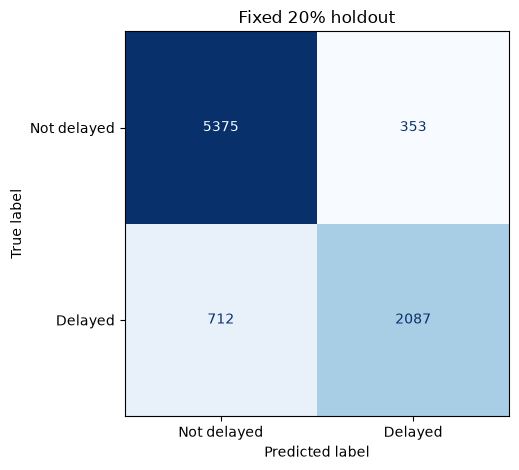

In [31]:
evaluation_model=ContextFlightClassifier(deepcopy(selected_spec)).fit(X_train,y_train)
holdout_score=evaluation_model.scores(X_holdout)
prediction=(holdout_score>=selected_threshold).astype(int)
metrics={
    'accuracy':accuracy_score(y_holdout,prediction),
    'weighted_precision':precision_score(y_holdout,prediction,average='weighted',zero_division=0),
    'weighted_recall':recall_score(y_holdout,prediction,average='weighted',zero_division=0),
    'weighted_f1':f1_score(y_holdout,prediction,average='weighted'),
    'macro_f1':f1_score(y_holdout,prediction,average='macro'),
    'delay_f1':f1_score(y_holdout,prediction,pos_label=1),
    'delay_precision':precision_score(y_holdout,prediction,zero_division=0),
    'delay_recall':recall_score(y_holdout,prediction),
    'balanced_accuracy':balanced_accuracy_score(y_holdout,prediction),
    'roc_auc':roc_auc_score(y_holdout,holdout_score)}
display(pd.Series(metrics,name='Fixed 20% holdout').to_frame().round(4))
print(classification_report(y_holdout,prediction,labels=[0,1],
    target_names=['Not delayed (0)','Delayed (1)'],digits=4,zero_division=0))
print('Holdout accuracy:',round(metrics['accuracy'],4))
print('Holdout weighted F1:',round(metrics['weighted_f1'],4))
print('Accuracy >= 0.87:',metrics['accuracy']>=.87)
print('Weighted F1 >= 0.87:',metrics['weighted_f1']>=.87)
ConfusionMatrixDisplay.from_predictions(y_holdout,prediction,labels=[0,1],
    display_labels=['Not delayed','Delayed'],cmap='Blues',colorbar=False)
plt.title('Fixed 20% holdout');plt.tight_layout();plt.show()

## Generate `catboost.csv`

    The selected configuration and validation cutoff are now fitted on **all labelled rows**. The entire unknown CSV is transformed as one batch, preserving the supplied order. Row IDs are copied exactly from the Kaggle sample. Its prediction placeholders are ignored. The only written artifact is `catboost.csv`; rerunning this cell replaces it. No submission to Kaggle occurs automatically.

In [32]:
print('Fitting the full-data submission model; please wait for the CSV success message.')
submission_model=ContextFlightClassifier(deepcopy(selected_spec)).fit(X,y)
unknown_score=submission_model.scores(unknown)
unknown_prediction=(unknown_score>=selected_threshold).astype(int)
submission=pd.DataFrame({'row ID':sample['row ID'].to_numpy(),
                         'Predicted_Arrival_Delay':unknown_prediction})
assert len(submission)==len(unknown)
assert list(submission.columns)==['row ID','Predicted_Arrival_Delay']
assert submission['row ID'].equals(sample['row ID'])
assert set(submission['Predicted_Arrival_Delay'].unique()).issubset({0,1})
OUTPUT_FILE=TRAIN_FILE.parent/f'{OUTPUT_STEM}.csv'
submission.to_csv(OUTPUT_FILE,index=False)
saved=pd.read_csv(OUTPUT_FILE,dtype={'row ID':str})
pd.testing.assert_frame_equal(saved,submission)
print('CSV generated successfully:',OUTPUT_FILE.resolve())
print('Rows:',len(saved),'| Columns:',list(saved.columns))
display(saved.head());display(FileLink(str(OUTPUT_FILE)))

Fitting the full-data submission model; please wait for the CSV success message.
Building cross-fitted flight-history features...
Building four label-free batch-context densities...
Fitting catboost...
CSV generated successfully: catboost.csv
Rows: 21318 | Columns: ['row ID', 'Predicted_Arrival_Delay']


,row ID,Predicted_Arrival_Delay
0,Row0,0
1,Row1,0
2,Row2,1
3,Row3,0
4,Row4,1


catboost.csv

## Reporting the result

    Report both accuracy and weighted F1 with their names. Do not describe the local score as a Kaggle score. Enter the actual public score only after manually submitting the generated CSV. Do not tune using public leaderboard feedback.

    Explain preprocessing, cross-fitting, density augmentation, validation selection and the confusion matrix. For an ordered-batch model, explain the source-order assumption and shuffled-order control prominently. These results are conditional on retrospective ordered-batch inputs; they do not establish generic online flight prediction. The high scores of other leaderboard participants do not reveal which methods they used.

    References: [scikit-learn data leakage](https://scikit-learn.org/stable/common_pitfalls.html), [TargetEncoder cross-fitting](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html), [classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics), [isotonic regression](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.isotonic_regression.html), [CatBoost](https://catboost.ai/docs/en/), [LightGBM](https://lightgbm.readthedocs.io/en/latest/).